# β-VAE (Higgins et al., ICLR 2017): Figure 7A and 7B from saved runs

This notebook **never trains**. It only reads what `train.py` / `run.sh` wrote to disk:

| File | Used for |
|---|---|
| `data/meta.npz` | factor grid (image index for every shape × scale × rotation × x × y), verified shape names, image orientation |
| `runs/<run>/status.json`, `config.json`, `log.jsonl` | run state and training curves |
| `runs/<run>/analysis.npz` | posterior mean μ of all 737,280 images, learnt variance, KL per latent |
| `runs/<run>/final.pt` | decoder weights for the traversal rows (forward passes only) |

Keep `train.py` next to this notebook: the model class is imported from it, so the architecture is defined once. No GPU and no dataset images are needed here.

## Setup behind Figure 7, as stated in the paper

| Item | What the paper says | Source |
|---|---|---|
| Data | 737,280 binary 64×64 images: 3 shapes (heart, oval, square) × pos X (32) × pos Y (32) × scale (6) × rotation (40 values over 2π) | Sec. 4.2 |
| Encoder | Input 4096 (flattened 64×64×1); FC 1200, 1200; ReLU | Table 1 (App. A.1), row "2D shapes (VAE)" |
| Latents | 10 | Table 1; App. A.4; Fig. 7 caption ("remaining 9/10") |
| Decoder | FC 1200, 1200, 1200, 4096; Tanh; Bernoulli output | Table 1 |
| Optimizer | Adagrad, learning rate 1e-2 | Table 1 |
| Posterior / prior | q(z\|x) = N(μ(x), σ(x)) diagonal; p(z) = N(0, I) | Sec. 2; Eq. 5 (App. A.4) |
| Objective | E_q[log p(x\|z)] − β·KL(q(z\|x) ‖ p(z)), pixel log-likelihoods summed | Eq. 4 (Sec. 2); Eq. 7 (App. A.6) |
| β | A: β = 4. B: β = 1, same architecture. Unnormalised (β_norm = βM/N ≈ 0.0098 for β = 4) | Fig. 7 caption; Sec. 4.2; App. A.4, A.6 |
| Column order | Ascending learnt Gaussian variance (last row); uninformative units have KL ≈ 0, one shown as Z_unused | Fig. 7 caption; Sec. 4.2 |
| Rows 1–3 | Mean μ_m vs. 32×32 position (averaged over shapes, rotations, scales); vs. scale and vs. rotation per shape (square red, oval green, heart blue) | Fig. 7 caption |
| Rows 4–8 | One latent swept over ±3 prior standard deviations, other 9 fixed at the inferred code of one dataset image; +3 at top | Fig. 7 caption; Fig. 7A axis |
| Training budget, batch size | Not stated | — |

## Assumptions where the paper is silent

1. Batch 64, uniform sampling with replacement; `full` = 500k iterations per run, `reduced` = 150k (set in `run.sh` / `train.py`).
2. Encoder head outputs μ and log σ²; one reparameterised sample; loss summed over pixels and latents, averaged over the batch; PyTorch default init and Adagrad settings; no clipping or schedule. Non-finite loss marks a run `diverged` and it is left as is.
3. The dataset is the dSprites release (matches Sec. 4.2); label columns verified from the images in `train.py --prepare-data`.
4. Learnt variance = posterior σ² averaged over all images.
5. Columns: every latent with data-averaged KL > `KL_ACTIVE`, ascending by learnt variance, plus one Z_unused if any exists.
6. Factor label under a column only if one factor explains > 50 % of Var(μ_m) (η², rotation within shape); else "mixed". The paper labels by inspection.
7. Traversal: 5 values from +3 to −3 around the code of `SEED_IMAGE`; decoded Bernoulli means shown.
8. jet colormap; colour limits and y-limits symmetric and shared within a panel.
9. All seeds are plotted; no seed is selected.

## 1. Configuration

In [1]:
import json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch

from train import model_from_config, run_name     # model definition lives in train.py only

RUN_DIR = Path('runs')
DATA_DIR = Path('data')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
BETAS = [1.0, 4.0]
SEEDS = [0, 1, 2]

KL_ACTIVE = 0.05                            # nats; data-averaged KL above which a latent is informative
TRAVERSAL_VALUES = np.linspace(3, -3, 5)    # top row = +3
SEED_IMAGE = dict(shape='oval', scale=3, rotation=8, pos_x=16, pos_y=16)   # class indices
SHAPE_COLORS = {'square': 'red', 'oval': 'green', 'heart': 'blue'}         # Fig. 7 caption
ETA_FACTORS = ['shape', 'scale', 'rotation', 'pos. X', 'pos. Y']

meta = np.load(DATA_DIR / 'meta.npz')
G = meta['G']                                # (shape, scale, rotation, pos_x, pos_y) -> image index
SHAPE_NAMES = {i: str(n) for i, n in enumerate(meta['shape_names'])}
POS_Y_DOWN = bool(meta['pos_y_down'])
print('shape classes', SHAPE_NAMES, '| grid', G.shape, '| pos_y increases downward:', POS_Y_DOWN)

shape classes {0: 'square', 1: 'oval', 2: 'heart'} | grid (3, 6, 40, 32, 32) | pos_y increases downward: True


## 2. Run status and training curves (from `log.jsonl`)

beta1_seed0    {'status': 'done', 'step': 500000}  n_iters=500000  analysis=yes
beta1_seed1    {'status': 'done', 'step': 500000}  n_iters=500000  analysis=yes
beta1_seed2    {'status': 'done', 'step': 500000}  n_iters=500000  analysis=yes
beta4_seed0    {'status': 'done', 'step': 500000}  n_iters=500000  analysis=yes
beta4_seed1    {'status': 'running', 'step': 300000}  n_iters=500000  analysis=no
beta4_seed2    None  n_iters=None  analysis=no


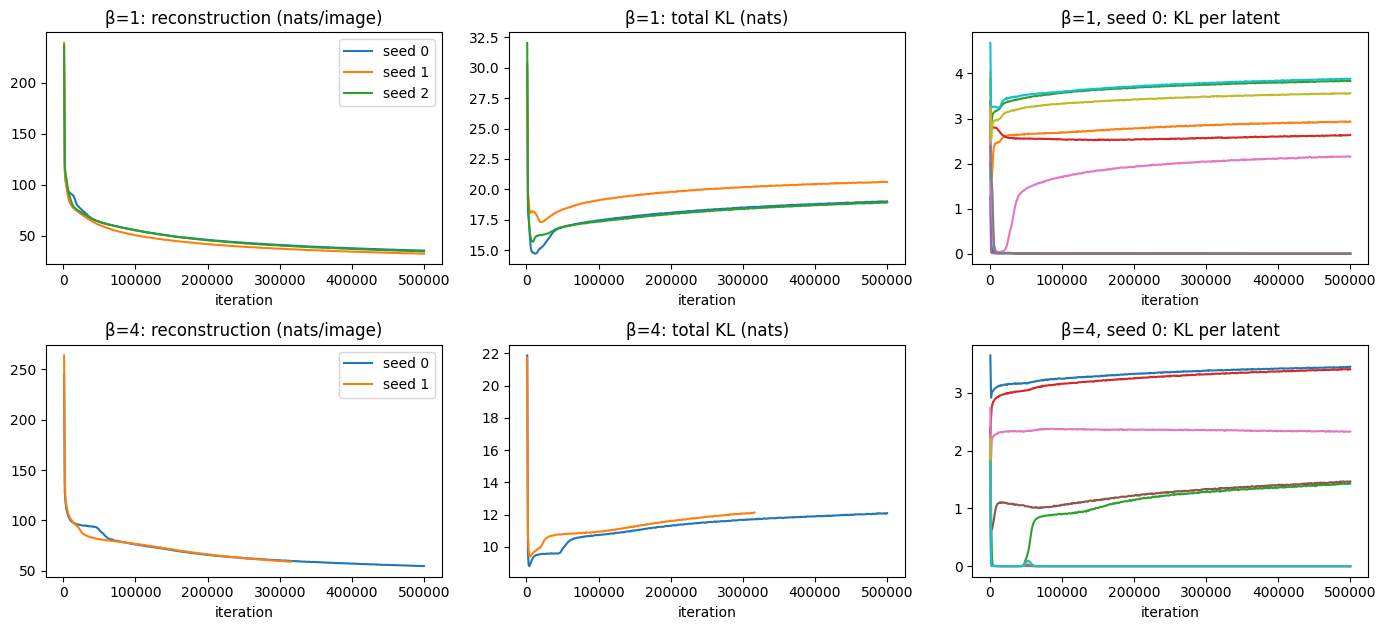

In [2]:
def read_json(p):
    return json.loads(p.read_text()) if p.exists() else None

def read_log(name):
    p = RUN_DIR / name / 'log.jsonl'
    return [json.loads(l) for l in p.read_text().splitlines()] if p.exists() else []

for beta in BETAS:
    for seed in SEEDS:
        name = run_name(beta, seed)
        st, cfg = read_json(RUN_DIR / name / 'status.json'), read_json(RUN_DIR / name / 'config.json')
        print(f"{name:14s} {st}  n_iters={cfg and cfg['n_iters']}  "
              f"analysis={'yes' if (RUN_DIR / name / 'analysis.npz').exists() else 'no'}")

fig, axes = plt.subplots(len(BETAS), 3, figsize=(14, 3.2 * len(BETAS)), squeeze=False)
for i, beta in enumerate(BETAS):
    for seed in SEEDS:
        L = read_log(run_name(beta, seed))
        if not L:
            continue
        s = [r['step'] for r in L]
        axes[i, 0].plot(s, [r['recon'] for r in L], label=f'seed {seed}')
        axes[i, 1].plot(s, [r['kl'] for r in L], label=f'seed {seed}')
        if seed == SEEDS[0]:
            axes[i, 2].plot(s, np.array([r['kl_per_latent'] for r in L]))
    axes[i, 0].set_title(f'β={beta:g}: reconstruction (nats/image)'); axes[i, 0].legend()
    axes[i, 1].set_title(f'β={beta:g}: total KL (nats)')
    axes[i, 2].set_title(f'β={beta:g}, seed {SEEDS[0]}: KL per latent')
    for a in axes[i]:
        a.set_xlabel('iteration')
plt.tight_layout(); plt.show()

## 3. Latent statistics from `analysis.npz`

Rows 1–3 are averages of the stored posterior means over the factor grid, plus η² scores used only for the column labels. Runs that are not `done` or have no `analysis.npz` are skipped with a message.

In [3]:
def latent_stats(name):
    A = np.load(RUN_DIR / name / 'analysis.npz')
    final_step = int(torch.load(RUN_DIR / name / 'final.pt', map_location='cpu', weights_only=True)['step'])
    if int(A['step']) != final_step:
        raise RuntimeError(f'{name}: analysis.npz is from step {int(A["step"])}, final.pt from {final_step}; '
                           f'run `python train.py --beta .. --seed .. --analyze-only`')
    mu = A['mu'].astype(np.float64)
    grid = mu[G]                                       # (shape, scale, rot, x, y, M)
    rot_curve = grid.mean(axis=(1, 3, 4))              # (shape, rot, M)
    tot = mu.var(0) + 1e-12
    eta = np.stack([
        grid.mean(axis=(1, 2, 3, 4)).var(0) / tot,                               # shape
        grid.mean(axis=(0, 2, 3, 4)).var(0) / tot,                               # scale
        (rot_curve - rot_curve.mean(1, keepdims=True)).var(axis=(0, 1)) / tot,   # rotation within shape
        grid.mean(axis=(0, 1, 2, 4)).var(0) / tot,                               # pos x
        grid.mean(axis=(0, 1, 2, 3)).var(0) / tot,                               # pos y
    ])
    return dict(mu=mu, pos_map=grid.mean(axis=(0, 1, 2)), scale_curve=grid.mean(axis=(2, 3, 4)),
                rot_curve=rot_curve, learnt_var=A['learnt_var'], kl=A['kl'], eta=eta, step=final_step)

STATS = {}
for beta in BETAS:
    for seed in SEEDS:
        name = run_name(beta, seed)
        st = read_json(RUN_DIR / name / 'status.json')
        if st and st['status'] == 'done' and (RUN_DIR / name / 'analysis.npz').exists():
            STATS[name] = latent_stats(name)
        else:
            print('skipping', name, st)
print('loaded:', list(STATS))

skipping beta4_seed1 {'status': 'running', 'step': 300000}
skipping beta4_seed2 None
loaded: ['beta1_seed0', 'beta1_seed1', 'beta1_seed2', 'beta4_seed0']


### Per-run summary (all seeds, no selection)

In [4]:
def factor_label(eta_col):
    j = int(np.argmax(eta_col))
    return ETA_FACTORS[j] if eta_col[j] > 0.5 else 'mixed'

for name, S in STATS.items():
    order = np.argsort(S['learnt_var'])
    active = [m for m in order if S['kl'][m] > KL_ACTIVE]
    print(f"{name} (step {S['step']}): {len(active)} informative latents")
    for m in order:
        tag = factor_label(S['eta'][:, m]) if m in active else 'unused'
        etas = ' '.join(f"{f}={S['eta'][k, m]:.2f}" for k, f in enumerate(ETA_FACTORS))
        print(f"   z{m + 1:<2d} var {S['learnt_var'][m]:.2f}  KL {S['kl'][m]:6.3f}  {tag:9s} | {etas}")

beta1_seed0 (step 500000): 6 informative latents
   z3  var 0.00  KL  3.843  mixed     | shape=0.00 scale=0.00 rotation=0.01 pos. X=0.31 pos. Y=0.46
   z10 var 0.00  KL  3.896  mixed     | shape=0.00 scale=0.00 rotation=0.01 pos. X=0.41 pos. Y=0.42
   z9  var 0.00  KL  3.551  mixed     | shape=0.02 scale=0.06 rotation=0.00 pos. X=0.45 pos. Y=0.37
   z2  var 0.00  KL  2.937  mixed     | shape=0.03 scale=0.04 rotation=0.17 pos. X=0.01 pos. Y=0.05
   z4  var 0.01  KL  2.633  mixed     | shape=0.09 scale=0.24 rotation=0.04 pos. X=0.07 pos. Y=0.01
   z7  var 0.02  KL  2.166  mixed     | shape=0.00 scale=0.00 rotation=0.04 pos. X=0.00 pos. Y=0.00
   z1  var 0.96  KL  0.001  unused    | shape=0.01 scale=0.00 rotation=0.01 pos. X=0.01 pos. Y=0.00
   z5  var 0.96  KL  0.001  unused    | shape=0.00 scale=0.00 rotation=0.01 pos. X=0.01 pos. Y=0.01
   z6  var 0.96  KL  0.001  unused    | shape=0.01 scale=0.00 rotation=0.01 pos. X=0.01 pos. Y=0.00
   z8  var 0.97  KL  0.001  unused    | shape=0.00 

## 4. Figure 7A and 7B

Column headers z_i; row 1 position map; rows 2–3 scale and rotation curves per shape; rows 4–8 single-latent traversals from +3 to −3 around the stored code of `SEED_IMAGE`; then learnt variance and factor label. The traversal images are decoder forward passes of `final.pt` on CPU.

In [5]:
def seed_image_index():
    inv = {v: k for k, v in SHAPE_NAMES.items()}
    s = SEED_IMAGE
    return int(G[inv[s['shape']], s['scale'], s['rotation'], s['pos_x'], s['pos_y']])


@torch.no_grad()
def traversals(name, cols):
    ck = torch.load(RUN_DIR / name / 'final.pt', map_location='cpu', weights_only=True)
    model = model_from_config(ck['config']); model.load_state_dict(ck['model']); model.eval()
    base = torch.tensor(STATS[name]['mu'][seed_image_index()], dtype=torch.float32)
    out = np.zeros((len(TRAVERSAL_VALUES), len(cols), 64, 64))
    for j, m in enumerate(cols):
        z = base.repeat(len(TRAVERSAL_VALUES), 1)
        z[:, m] = torch.tensor(TRAVERSAL_VALUES, dtype=torch.float32)
        out[:, j] = torch.sigmoid(model.decode(z)).view(-1, 64, 64).numpy()
    return out


def choose_columns(S):
    order = list(np.argsort(S['learnt_var']))
    active = [m for m in order if S['kl'][m] > KL_ACTIVE]
    unused = [m for m in order if S['kl'][m] <= KL_ACTIVE]
    cols, heads = list(active), [f'$z_{{{m + 1}}}$' for m in active]
    labels = [factor_label(S['eta'][:, m]) for m in active]
    if unused:
        cols.append(unused[-1]); heads.append('$Z_{unused}$'); labels.append('')
    return cols, heads, labels


def draw_panel(sf, name, title, letter):
    S = STATS[name]
    cols, heads, labels = choose_columns(S)
    trav = traversals(name, cols)
    nc, nt = len(cols), len(TRAVERSAL_VALUES)
    gs = sf.add_gridspec(4 + nt, nc, height_ratios=[1, 0.55, 0.55, 0.08] + [1] * nt,
                         hspace=0.06, wspace=0.06, left=0.14, right=0.98, top=0.88, bottom=0.10)
    vmax = np.abs(S['pos_map'][..., cols]).max()
    ylim_s = np.abs(S['scale_curve'][..., cols]).max() * 1.1
    ylim_r = np.abs(S['rot_curve'][..., cols]).max() * 1.1
    col0 = {}
    for j, m in enumerate(cols):
        ax = sf.add_subplot(gs[0, j])
        ax.imshow(S['pos_map'][:, :, m].T, cmap='jet', vmin=-vmax, vmax=vmax,     # rows = pos y
                  origin='upper' if POS_Y_DOWN else 'lower', interpolation='bilinear')
        ax.set_title(heads[j], fontsize=11)
        if j == 0: col0['position'] = ax
        for r, (key, lim, lab) in enumerate([('scale_curve', ylim_s, 'scale'),
                                             ('rot_curve', ylim_r, 'rotation')], start=1):
            ax = sf.add_subplot(gs[r, j])
            for s, sname in SHAPE_NAMES.items():
                ax.plot(S[key][s, :, m], color=SHAPE_COLORS[sname], lw=0.9)
            ax.set_ylim(-lim, lim); ax.set_xlim(0, S[key].shape[1] - 1)
            ax.axhline(0, color='k', lw=0.3, ls=':')
            if j == 0: col0[lab] = ax
        for t in range(nt):
            ax = sf.add_subplot(gs[4 + t, j])
            ax.imshow(trav[t, j], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            if j == 0 and t == 0: col0['top'] = ax
            if j == 0 and t == nt - 1: col0['bottom'] = ax
            if t == nt - 1:
                ax.text(0.5, -0.12, f"{S['learnt_var'][m]:.2f}", transform=ax.transAxes,
                        ha='center', va='top', fontsize=10)
                ax.text(0.5, -0.42, labels[j], transform=ax.transAxes, ha='center', va='top', fontsize=8)
    for ax in sf.axes:
        ax.set_xticks([]); ax.set_yticks([])
    for lab in ['position', 'scale', 'rotation']:
        col0[lab].set_ylabel(lab, fontsize=8)
    col0['top'].set_ylabel(f'{TRAVERSAL_VALUES[0]:g}', fontsize=9, rotation=0, ha='right', va='top')
    col0['bottom'].set_ylabel(f'{TRAVERSAL_VALUES[-1]:g}', fontsize=9, rotation=0, ha='right', va='bottom')
    sf.add_artist(ConnectionPatch((-0.30, 0.95), (-0.30, 0.05), 'axes fraction', 'axes fraction',
                                  axesA=col0['top'], axesB=col0['bottom'], arrowstyle='->', color='k', lw=0.8))
    sf.text(0.02, 0.73, 'mean latent response', rotation=90, ha='left', va='center', fontsize=9, weight='bold')
    sf.text(0.02, 0.35, 'single latent mean traversal', rotation=90, ha='left', va='center', fontsize=9, weight='bold')
    sf.text(0.02, 0.05, 'learnt\nvariance', ha='left', va='center', fontsize=8)
    sf.suptitle(f'{letter}    {title}', x=0.14, ha='left', fontsize=13, weight='bold')


def figure7(seed, save=True):
    names = {4.0: run_name(4.0, seed), 1.0: run_name(1.0, seed)}
    missing = [n for n in names.values() if n not in STATS]
    if missing:
        print('cannot draw seed', seed, '- missing', missing); return
    widths = [len(choose_columns(STATS[names[b]])[0]) + 1.2 for b in (4.0, 1.0)]
    col_in = 0.95                                            # inches per latent column
    nrows_h = 1 + 0.55 + 0.55 + 0.08 + len(TRAVERSAL_VALUES)
    fig = plt.figure(figsize=(col_in * sum(widths), col_in * nrows_h / 0.78 + 0.4))
    sfA, sfB = fig.subfigures(1, 2, width_ratios=widths, wspace=0.02)
    draw_panel(sfA, names[4.0], r'$\beta$-VAE ($\beta=4$)', 'A')
    draw_panel(sfB, names[1.0], r'VAE ($\beta=1$)', 'B')
    fig.text(0.995, 0.995, f'seed {seed}', ha='right', va='top', fontsize=9, color='0.4')
    if save:
        for ext in ['png', 'pdf']:
            fig.savefig(FIG_DIR / f'figure7AB_seed{seed}.{ext}', dpi=150, bbox_inches='tight')
    plt.show()

### One figure per seed

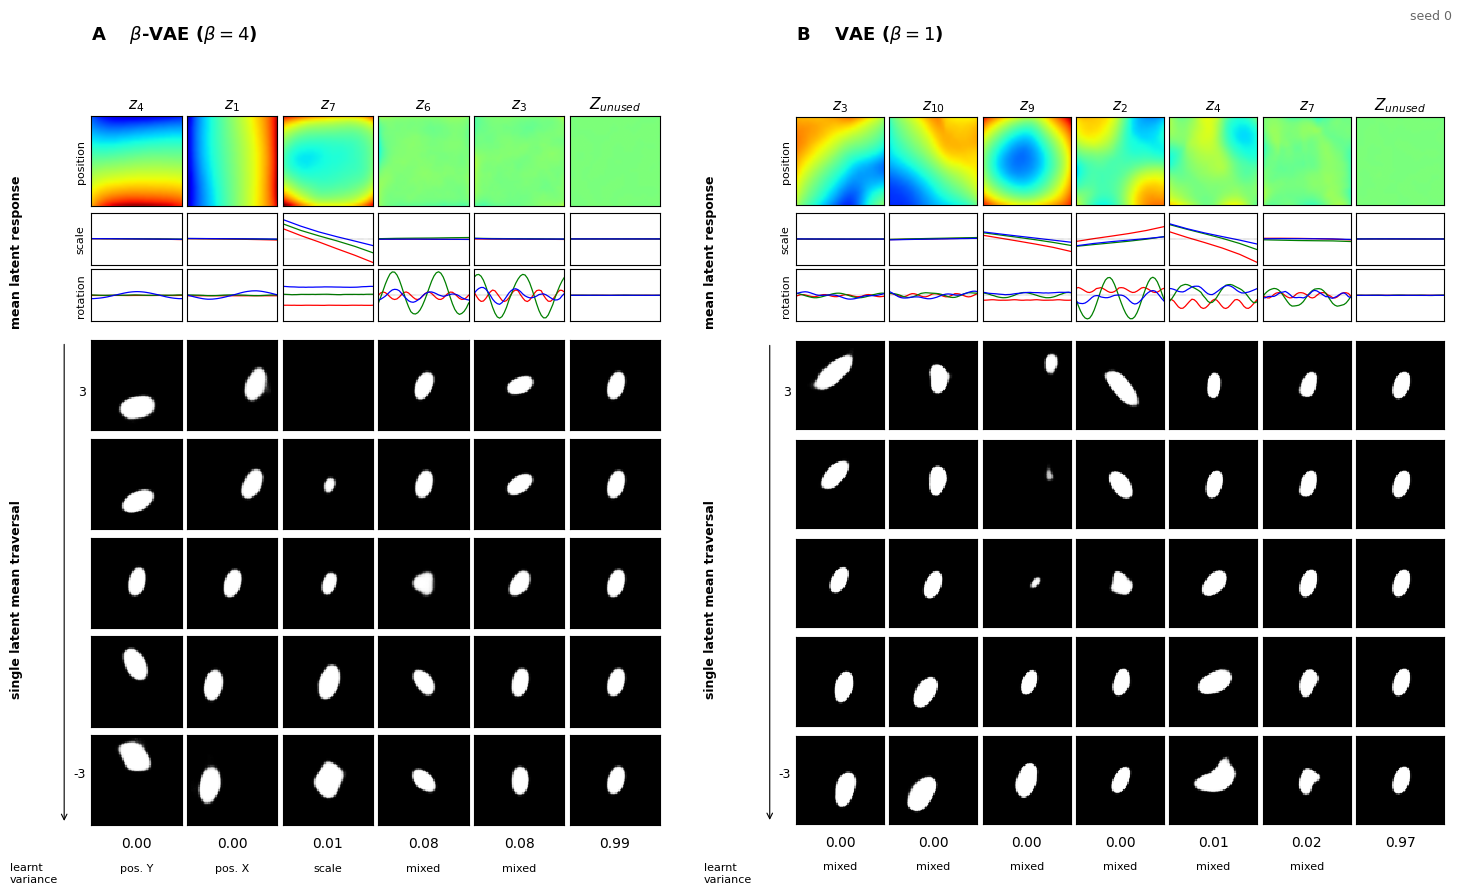

cannot draw seed 1 - missing ['beta4_seed1']
cannot draw seed 2 - missing ['beta4_seed2']


In [6]:
for seed in SEEDS:
    figure7(seed)